# Statistical Analysis — US Accidents Dataset

**Axis 1 — What factors influence accident severity?**
**Axis 2 — How do environmental conditions affect distance and severity?**

Uses the 500k random sample produced by `01_EDA.ipynb` 

Mechanisms:
- Axis 1: descriptive statistics, Chi-square, Cramér's V, one-way ANOVA, Tukey post-hoc, eta squared, logistic regression, odds ratios, AUC
- Axis 2: Pearson, Spearman, partial correlation, multiple linear regression + diagnostics, VIF, PCA


---


## 0. Imports and data loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', 60)
plt.rcParams['figure.figsize'] = (10, 5)


In [ ]:
from pathlib import Path

DATA_DIR = Path("D:/Accidents_USA/Dataset")   
DATA_PATH = DATA_DIR / "D:\\US\\Dataset\\US_Accidents_Sample500k_Clean.csv"   

df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")


Shape: 500,000 rows x 32 columns


---
# Axis 1 — What factors influence accident severity?

## 1. Descriptive statistics on Severity

count    500000.000000
mean          2.325726
std           0.534491
min           1.000000
25%           2.000000
50%           2.000000
75%           3.000000
max           4.000000
Name: Severity, dtype: float64
Mode: 2
IQR: 1.0


,share
Severity,
1,0.0277
2,0.6243
3,0.3427
4,0.0053


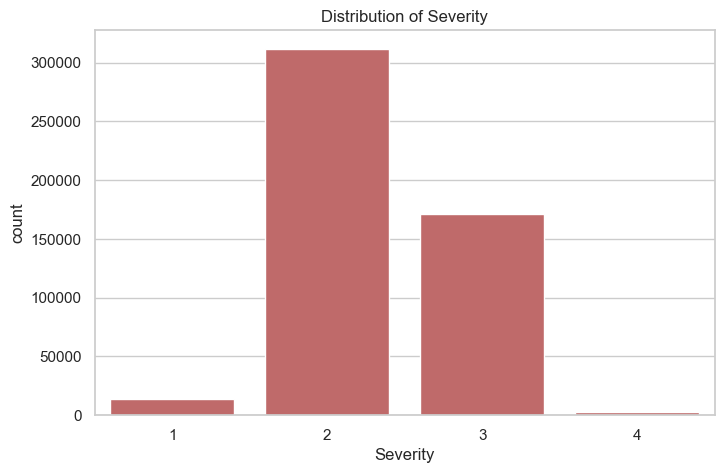

In [3]:
print(df['Severity'].describe())
print(f"Mode: {df['Severity'].mode()[0]}")
print(f"IQR: {df['Severity'].quantile(0.75) - df['Severity'].quantile(0.25)}")

display(df['Severity'].value_counts(normalize=True).sort_index().round(4).to_frame('share'))

plt.figure(figsize=(8, 5))
sns.countplot(x='Severity', data=df, color='indianred')
plt.title("Distribution of Severity")
plt.show()


## 2. Chi-square test — Weather_Condition vs Severity



In [4]:
top_weather = df['Weather_Condition'].value_counts().head(8).index
subset = df[df['Weather_Condition'].isin(top_weather)]

contingency = pd.crosstab(subset['Weather_Condition'], subset['Severity'])
chi2, p_value, dof, expected = chi2_contingency(contingency)
print(f"Chi2 = {chi2:.2f}, dof = {dof}, p-value = {p_value:.4g}")
print(f"Smallest expected count: {expected.min():.1f} (should be >= 5 for the test to be valid)")
contingency


Chi2 = 8249.50, dof = 21, p-value = 0
Smallest expected count: 86.0 (should be >= 5 for the test to be valid)


Severity,1,2,3,4
Weather_Condition,,,,
Clear,67,47094,26417,26
Cloudy,1626,30733,15477,400
Fair,7340,97909,44906,1146
Light Rain,323,12684,8517,113
Mostly Cloudy,2055,39275,24360,365
Overcast,15,18231,10140,16
Partly Cloudy,1466,26594,16467,236
Scattered Clouds,14,10183,6536,13


In [5]:
# Row percentages are far easier to read than raw counts
(pd.crosstab(subset['Weather_Condition'], subset['Severity'], normalize='index') * 100).round(1)


Severity,1,2,3,4
Weather_Condition,,,,
Clear,0.1,64.0,35.9,0.0
Cloudy,3.4,63.7,32.1,0.8
Fair,4.9,64.7,29.7,0.8
Light Rain,1.5,58.6,39.4,0.5
Mostly Cloudy,3.1,59.5,36.9,0.6
Overcast,0.1,64.2,35.7,0.1
Partly Cloudy,3.3,59.4,36.8,0.5
Scattered Clouds,0.1,60.8,39.0,0.1


### 2.1 Cramér's V — strength of the association

In [6]:
def cramers_v(table):
    chi2_val = chi2_contingency(table)[0]
    n = table.to_numpy().sum()
    return np.sqrt(chi2_val / (n * (min(table.shape) - 1)))

v = cramers_v(contingency)
print(f"Cramer's V = {v:.4f}")


Cramer's V = 0.0781


## 3. One-way ANOVA — Severity by Weather_Condition



In [7]:
groups = [subset.loc[subset['Weather_Condition'] == w, 'Severity'] for w in top_weather]
f_stat, p_anova = stats.f_oneway(*groups)
print(f"F = {f_stat:.2f}, p-value = {p_anova:.4g}")

subset.groupby('Weather_Condition')['Severity'].agg(['mean', 'count']).sort_values('mean', ascending=False).round(3)


F = 463.34, p-value = 0


,mean,count
Weather_Condition,,
Scattered Clouds,2.391,16746
Light Rain,2.389,21637
Clear,2.359,73604
Overcast,2.358,28402
Mostly Cloudy,2.349,66055
Partly Cloudy,2.346,44763
Cloudy,2.304,48236
Fair,2.263,151301


### 3.1 Tukey post-hoc test — which pairs differ?

In [8]:
tukey = pairwise_tukeyhsd(endog=subset['Severity'], groups=subset['Weather_Condition'], alpha=0.05)
tukey_df = pd.DataFrame(tukey.summary().data[1:], columns=tukey.summary().data[0])
tukey_df['meandiff'] = tukey_df['meandiff'].astype(float)
tukey_df.loc[tukey_df['reject'] == True].sort_values('meandiff', key=abs, ascending=False).head(10)


,group1,group2,meandiff,p-adj,lower,upper,reject
17,Fair,Scattered Clouds,0.1276,0.0,0.1144,0.1407,True
13,Fair,Light Rain,0.1257,0.0,0.1140,0.1374,True
1,Clear,Fair,-0.0953,0.0,-0.1025,-0.0880,True
15,Fair,Overcast,0.0942,0.0,0.0837,0.1046,True
12,Cloudy,Scattered Clouds,0.0873,0.0,0.0728,0.1018,True
8,Cloudy,Light Rain,0.0854,0.0,0.0722,0.0986,True
14,Fair,Mostly Cloudy,0.0853,0.0,0.0778,0.0928,True
16,Fair,Partly Cloudy,0.0822,0.0,0.0735,0.0909,True
0,Clear,Cloudy,-0.0550,0.0,-0.0644,-0.0455,True
10,Cloudy,Overcast,0.0539,0.0,0.0418,0.0659,True


### 3.2 Effect size — eta squared

In [9]:
dfn = len(top_weather) - 1
dfd = len(subset) - len(top_weather)
eta2 = (f_stat * dfn) / (f_stat * dfn + dfd)
print(f"Eta squared = {eta2:.4f}  ({eta2 * 100:.2f}% of the variance of Severity explained by weather)")


Eta squared = 0.0071  (0.71% of the variance of Severity explained by weather)


## 4. Logistic regression — predicting a severe accident (Severity >= 3)

In [10]:
df['is_severe'] = (df['Severity'] >= 3).astype(int)
print(f"Share of severe accidents (Severity >= 3): {df['is_severe'].mean() * 100:.1f}%")

predictors = ['Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)']
model_df = df.dropna(subset=predictors + ['is_severe']).copy()
print(f"Rows used (no missing predictor): {len(model_df):,} of {len(df):,}")

X = sm.add_constant(model_df[predictors])
y = model_df['is_severe']

logit_model = sm.Logit(y, X).fit(disp=0)
print(logit_model.summary())


Share of severe accidents (Severity >= 3): 34.8%
Rows used (no missing predictor): 325,992 of 500,000
                           Logit Regression Results                           
Dep. Variable:              is_severe   No. Observations:               325992
Model:                          Logit   Df Residuals:                   325988
Method:                           MLE   Df Model:                            3
Date:                Sun, 25 Oct 2026   Pseudo R-squ.:                0.006046
Time:                        17:56:06   Log-Likelihood:            -2.0656e+05
converged:                       True   LL-Null:                   -2.0781e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -0.9108      0.014    -63.769      0.000      -0.939      -0.883
Visibili

### 4.1 Odds ratios

In [11]:
odds = np.exp(logit_model.params).rename('Odds Ratio')
ci = np.exp(logit_model.conf_int())
ci.columns = ['2.5%', '97.5%']
odds_ratios_df = pd.concat([odds, ci], axis=1)
odds_ratios_df


,Odds Ratio,2.5%,97.5%
const,0.402207,0.391104,0.413625
Visibility(mi),0.996890,0.994098,0.999689
Wind_Speed(mph),1.034861,1.033445,1.036279
Precipitation(in),1.248023,1.175602,1.324905


### 4.2 Discrimination power — AUC

In [12]:
auc = roc_auc_score(y, logit_model.predict(X))
print(f"AUC = {auc:.3f}")


AUC = 0.556


---
# Axis 2 — How do environmental conditions affect distance and severity?

## 10. Pearson correlation — Distance(mi) vs Wind_Speed(mph)

Pearson r = 0.0019, p-value = 0.1754


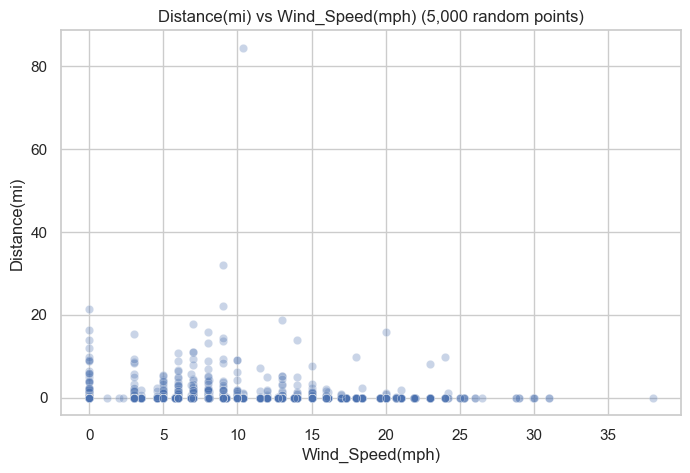

In [13]:
pair = df[['Distance(mi)', 'Wind_Speed(mph)']].dropna()
r, p = stats.pearsonr(pair['Distance(mi)'], pair['Wind_Speed(mph)'])
print(f"Pearson r = {r:.4f}, p-value = {p:.4g}")

plt.figure(figsize=(8, 5))
sns.scatterplot(x='Wind_Speed(mph)', y='Distance(mi)', data=pair.sample(5000, random_state=42), alpha=0.3)
plt.title("Distance(mi) vs Wind_Speed(mph) (5,000 random points)")
plt.show()


## 11. Spearman correlation — Severity vs Visibility(mi) and Distance(mi) vs Wind_Speed(mph)

In [14]:
pair1 = df[['Severity', 'Visibility(mi)']].dropna()
rho1, p1 = stats.spearmanr(pair1['Severity'], pair1['Visibility(mi)'])
print(f"Severity vs Visibility: rho = {rho1:.4f}, p-value = {p1:.4g}")

rho2, p2 = stats.spearmanr(pair['Distance(mi)'], pair['Wind_Speed(mph)'])
print(f"Distance vs Wind_Speed: rho = {rho2:.4f}, p-value = {p2:.4g}  (compare with Pearson r = {r:.4f})")


Severity vs Visibility: rho = -0.0004, p-value = 0.7506
Distance vs Wind_Speed: rho = 0.0895, p-value = 0  (compare with Pearson r = 0.0019)


## 12. Partial correlation — Severity vs Distance(mi), controlling for Wind_Speed(mph)

In [15]:
def partial_corr(x, y, z):
    rxy = np.corrcoef(x, y)[0, 1]
    rxz = np.corrcoef(x, z)[0, 1]
    ryz = np.corrcoef(y, z)[0, 1]
    return (rxy - rxz * ryz) / np.sqrt((1 - rxz ** 2) * (1 - ryz ** 2))

pc = df[['Severity', 'Distance(mi)', 'Wind_Speed(mph)']].dropna()
raw_r = np.corrcoef(pc['Severity'], pc['Distance(mi)'])[0, 1]
part_r = partial_corr(pc['Severity'].values, pc['Distance(mi)'].values, pc['Wind_Speed(mph)'].values)
print(f"Raw correlation Severity-Distance:     {raw_r:.4f}")
print(f"Partial correlation (control: wind):   {part_r:.4f}")


Raw correlation Severity-Distance:     0.1124
Partial correlation (control: wind):   0.1125


## 13. Multiple linear regression — Severity ~ Visibility + Wind_Speed + Precipitation

In [16]:
ols_model = smf.ols(
    'Severity ~ Q("Visibility(mi)") + Q("Wind_Speed(mph)") + Q("Precipitation(in)")',
    data=model_df
).fit()
print(ols_model.summary())


                            OLS Regression Results                            
Dep. Variable:               Severity   R-squared:                       0.008
Model:                            OLS   Adj. R-squared:                  0.008
Method:                 Least Squares   F-statistic:                     879.3
Date:                Sun, 25 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:56:40   Log-Likelihood:            -2.6912e+05
No. Observations:              325992   AIC:                         5.383e+05
Df Residuals:                  325988   BIC:                         5.383e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  2

### 13.1 Residual diagnostics

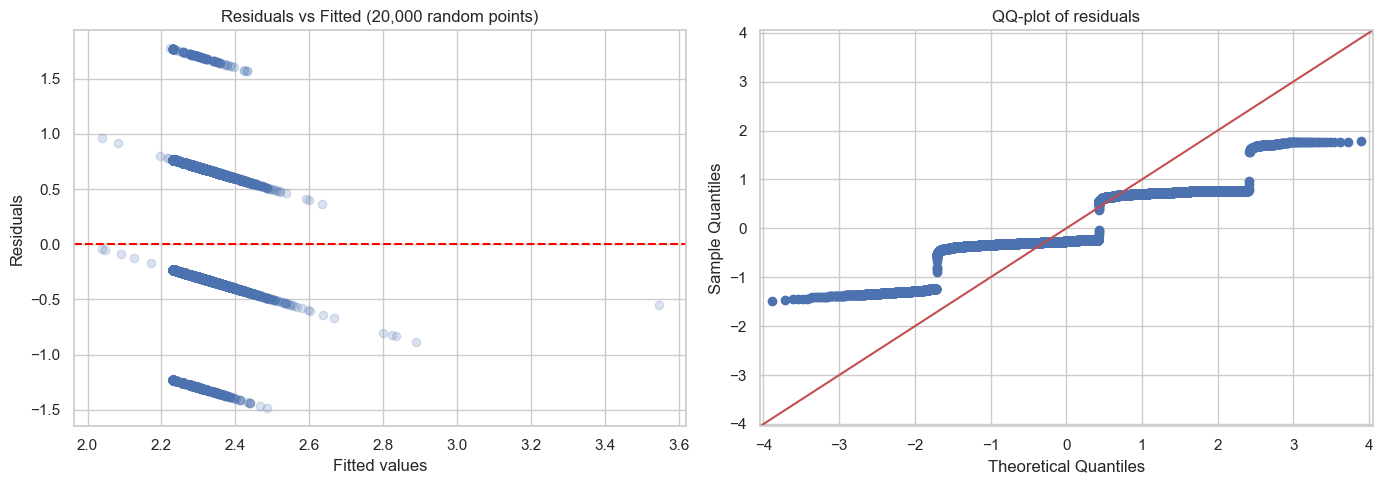

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
idx = np.random.default_rng(42).choice(len(ols_model.resid), size=min(20000, len(ols_model.resid)), replace=False)
axes[0].scatter(ols_model.fittedvalues.iloc[idx], ols_model.resid.iloc[idx], alpha=0.2)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Fitted values")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Fitted (20,000 random points)")
sm.qqplot(ols_model.resid.iloc[idx], line='45', ax=axes[1])
axes[1].set_title("QQ-plot of residuals")
plt.tight_layout()
plt.show()


## 14. VIF — multicollinearity

In [18]:
X_vif = sm.add_constant(model_df[predictors])
vif = pd.DataFrame({
    'variable': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
vif[vif['variable'] != 'const']


,variable,VIF
1,Visibility(mi),1.008645
2,Wind_Speed(mph),1.000655
3,Precipitation(in),1.009101


## 15. PCA on the weather variables

Explained variance per component: [0.326 0.212 0.196 0.16  0.106]
Cumulative:                       [0.326 0.538 0.733 0.894 1.   ]


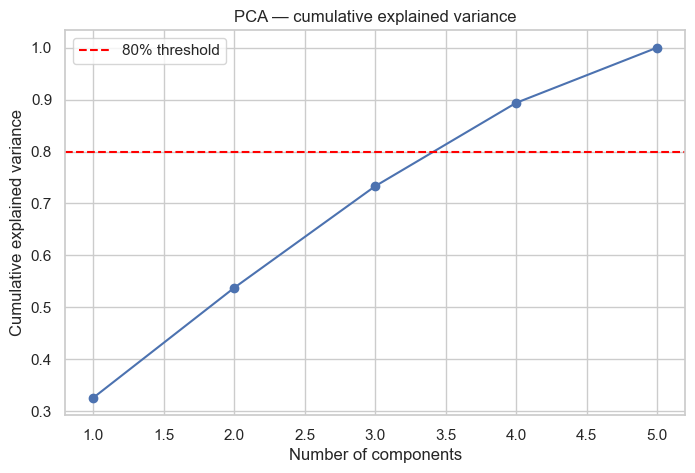

In [19]:
weather_cols = ['Temperature(F)', 'Humidity(%)', 'Wind_Speed(mph)', 'Pressure(in)', 'Visibility(mi)']
pca_df = df[weather_cols].dropna()

scaled = StandardScaler().fit_transform(pca_df)
pca = PCA(n_components=len(weather_cols)).fit(scaled)

explained = pca.explained_variance_ratio_
print("Explained variance per component:", np.round(explained, 3))
print("Cumulative:                      ", np.round(np.cumsum(explained), 3))

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained) + 1), np.cumsum(explained), marker='o')
plt.axhline(0.8, color='red', linestyle='--', label='80% threshold')
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA — cumulative explained variance")
plt.legend()
plt.show()


In [20]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i + 1}' for i in range(len(weather_cols))],
    index=weather_cols
)
loadings.iloc[:, :2].round(3)


,PC1,PC2
Temperature(F),-0.467,0.394
Humidity(%),0.644,0.152
Wind_Speed(mph),-0.249,-0.323
Pressure(in),0.102,0.834
Visibility(mi),-0.543,0.146
